In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'Q2.csv')
df.head()

,1,2,3,4,5,6,7,8,9,10,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000
0,13,29,44,55,61,72,200,96,112,120,...,21680,21692,21697,21705,21711,21729,21742,21746,21763,21777
1,-3980,-3883,-3832,0,-3839,-3788,-3695,-3663,-3669,0,...,7130,7150,7117,7023,7064,0,7027,6929,6954,6867
2,-3959,-4058,-4131,-4033,-4009,-3941,-3996,-4071,-3971,-4021,...,-254,-296,-303,0,-327,-274,-358,-278,-346,-299


In [3]:
columns = df.columns.to_numpy()
# تغییر شکل نام ستون‌ها به یک آرایه ستونی
reshaped_columns = columns.reshape(-1, 1)
reshaped_columns 

array([['1'],
       ['2'],
       ['3'],
       ...,
       ['1998'],
       ['1999'],
       ['2000']], dtype=object)

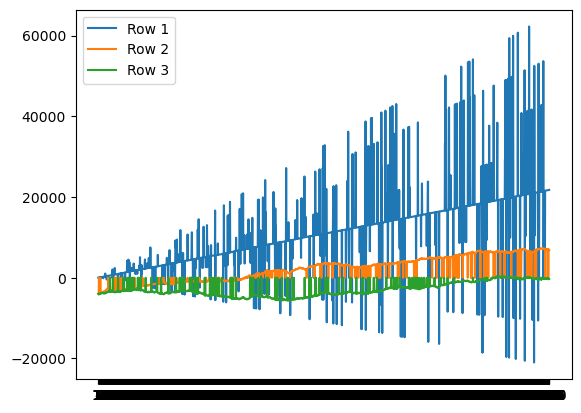

In [4]:
# رسم هر ردیف با رنگ‌های مختلف
for i in range(df.shape[0]):
    plt.plot(df.columns, df.iloc[i], label=f'Row {i+1}')

# برچسب زدن به محور‌ها و اضافه کردن شرح

plt.legend()

# نمایش نمودار
plt.show()

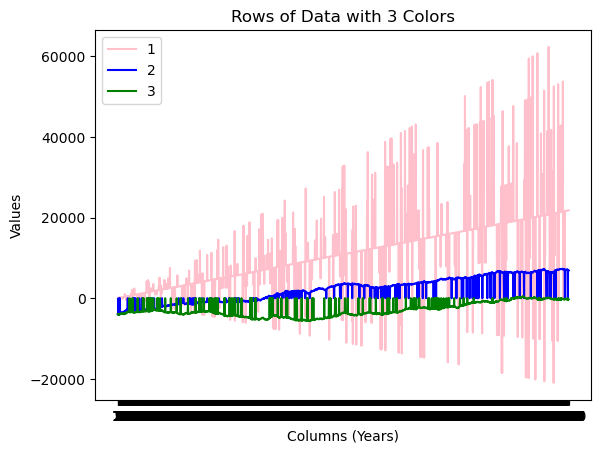

In [5]:
colors=['pink','blue','green']
for i ,row in df.iterrows():
  plt.plot(row.index,row.values, label=f'{i+1}',color=colors[i])

plt.xlabel('Columns (Years)')
plt.ylabel('Values')
plt.title('Rows of Data with 3 Colors')
plt.legend()
plt.show()

In [6]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

# شناسایی داده‌های پرت
outliers = (df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))
# نمایش داده‌های پرت
outliers_rows = df[outliers.any(axis=1)]  # ردیف‌هایی که حداقل یک داده پرت دارند
outliers_rows

,1,2,3,4,5,6,7,8,9,10,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000


In [93]:
from scipy.stats import zscore

# محاسبه Z-score برای هر مقدار
z_scores = zscore(df)

# شناسایی داده‌های پرت (Z-score > 3 یا < -3)
outliers = (z_scores > 3) | (z_scores < -3)

# نمایش داده‌های پرت
outliers_rows = df[outliers.any(axis=1)]
print(outliers_rows)
#########اینجا هیچ داده پرتی شاناسیایی نشد

Empty DataFrame
Columns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, ...]
Index: []

[0 rows x 2000 columns]


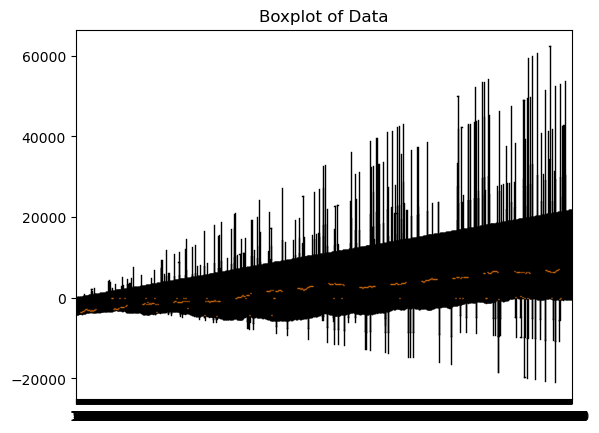

In [8]:
import matplotlib.pyplot as plt

# رسم نمودار Boxplot برای شناسایی داده‌های پرت
plt.boxplot(df.values)
plt.title('Boxplot of Data')
plt.show()

In [9]:
row_1 = df.iloc[0]
row_1

1          13.0
2          29.0
3          44.0
4          55.0
5          61.0
         ...   
1996    21729.0
1997    21742.0
1998    21746.0
1999    21763.0
2000    21777.0
Name: 0, Length: 2000, dtype: float64

In [101]:
row_1 = df.iloc[0]

# 2. پاکسازی داده‌ها با IQR:
Q1 = np.percentile(df.iloc[0].values, 25)  # 25 درصد پایین
Q3 = np.percentile(df.iloc[0].values, 75)  # 75 درصد بالا
IQR = Q3 - Q1  # محاسبه IQR
lower_bound = Q1 - 1.5 * IQR  # حد پایین
upper_bound = Q3 + 1.5 * IQR  # حد بالا

# شناسایی داده‌های پرت (outliers) با استفاده از IQR
outliers_iqr = (row_1 < lower_bound) | (row_1 > upper_bound)

#  Z-Score
z_scores = zscore(row_1.values.reshape(1, -1)).flatten()  # Reshape to 2D array and flatten result
outliers_zscore = (z_scores > 3) | (z_scores < -3)
outliers_iqr_values = row_1[outliers_iqr]
outliers_zscore_values = row_1[outliers_zscore]

#print("Datan with IQR method: ", outliers_iqr_values)
print("Data with Z-score method: ", outliers_zscore_values)

Data with Z-score method:  Series([], Name: 0, dtype: float64)


In [47]:
# حذف داده‌های پرت با استفاده از روش IQR
row_1_no_outliers = row_1[~outliers_iqr]
print("Row without outliers (IQR method):")
print(row_1_no_outliers)


Row without outliers (IQR method):
1          13.0
2          29.0
3          44.0
4          55.0
5          61.0
         ...   
1996    21729.0
1997    21742.0
1998    21746.0
1999    21763.0
2000    21777.0
Name: 0, Length: 1935, dtype: float64


In [21]:
# جایگزینی داده‌های پرت با میانگین همسایه‌ها
row_1_with_imputation = row_1.copy()

# جایگزینی داده‌های پرت با میانگین همسایگان
for index in row_1.index[outliers_iqr]:
    # پیدا کردن همسایگان (قبل و بعد از داده پرت)
    prev_index = row_1.index.get_loc(index) - 1
    next_index = row_1.index.get_loc(index) + 1
    # جایگزینی با میانگین همسایگان
    if prev_index >= 0 and next_index < len(row_1):
        row_1_with_imputation[index] = row_1.iloc[prev_index:next_index+1].mean()

# نمایش نتایج
print("Row with outliers replaced by neighboring mean:")
print(row_1_with_imputation)

Row with outliers replaced by neighboring mean:
1          13.0
2          29.0
3          44.0
4          55.0
5          61.0
         ...   
1996    21729.0
1997    21742.0
1998    21746.0
1999    21763.0
2000    21777.0
Name: 0, Length: 2000, dtype: float64


In [49]:
row_1_with_imputation=pd.DataFrame(row_1_with_imputation)
row_1_with_imputation.isnull().sum()

0    0
dtype: int64

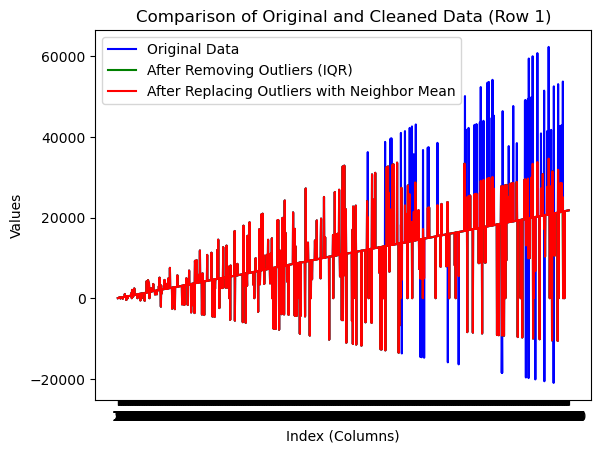

In [51]:
# رسم داده‌های اصلی (ردیف اول)
plt.plot(row_1, label='Original Data', color='blue')

# رسم داده‌های پاکسازی شده (پس از حذف داده‌های پرت)
plt.plot(row_1_no_outliers, label='After Removing Outliers (IQR)', color='green')

# رسم داده‌های پاکسازی شده (پس از جایگزینی داده‌های پرت با میانگین همسایگان)
plt.plot(row_1_with_imputation, label='After Replacing Outliers with Neighbor Mean', color='red')

# تنظیمات نمودار
plt.xlabel('Index (Columns)')
plt.ylabel('Values')
plt.title('Comparison of Original and Cleaned Data (Row 1)')
plt.legend()

plt.show()

Model parameters for cleaned data (No Outliers) (Normal Equation):
Intercept (B0): 10275.64418604651
Slope (B1): 7433.43795399564

Model parameters for cleaned data (Imputation) (Normal Equation):
Intercept (B0): [10654.93583333]
Slope (B1): [7768.1481792]


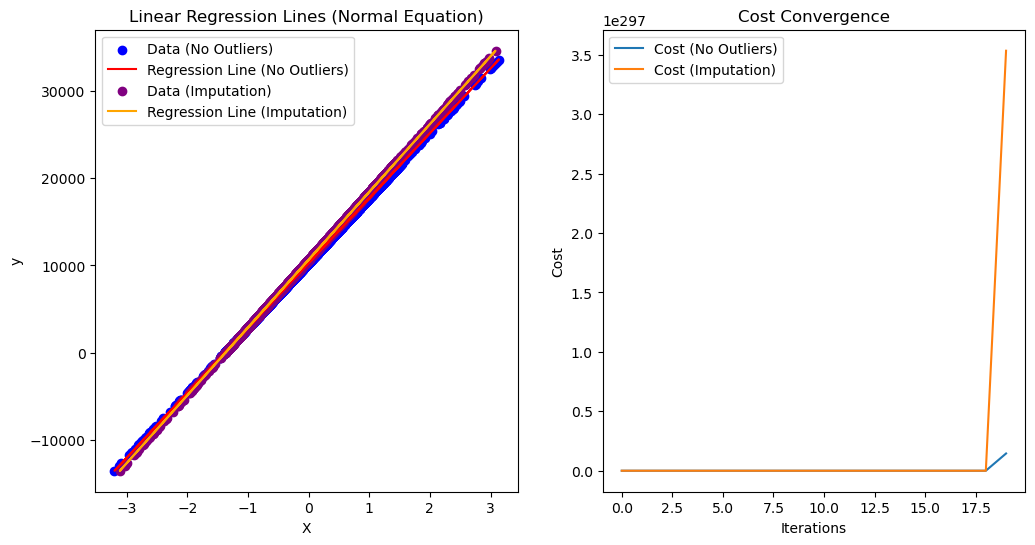

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# آماده‌سازی داده‌ها برای رگرسیون (اضافه کردن ستون 1 برای بایاس)
X_cleaned_no_outliers = np.c_[np.ones(len(row_1_no_outliers)), row_1_no_outliers]
X_cleaned_with_imputation = np.c_[np.ones(len(row_1_with_imputation)), row_1_with_imputation]

# مقیاس‌بندی داده‌ها برای جلوگیری از NaN در محاسبات
#scaler = StandardScaler()

# مقیاس‌بندی داده‌های پاکسازی‌شده (حذف داده‌های پرت و جایگزینی با میانگین همسایه‌ها)
X_scaled_no_outliers = scaler.fit_transform(X_cleaned_no_outliers[:, 1].reshape(-1, 1))  # مقیاس‌بندی ویژگی
X_scaled_with_imputation = scaler.fit_transform(X_cleaned_with_imputation[:, 1].reshape(-1, 1))  # مقیاس‌بندی ویژگی

# اضافه کردن ستون 1 برای بایاس
X_scaled_no_outliers = np.c_[np.ones(X_scaled_no_outliers.shape[0]), X_scaled_no_outliers]
X_scaled_with_imputation = np.c_[np.ones(X_scaled_with_imputation.shape[0]), X_scaled_with_imputation]

# مدل رگرسیون خطی از صفر (با استفاده از معادله عادی)
def linear_regression_model(X, y):
    # حل معادله عادی برای به دست آوردن theta
    theta = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)
    return theta

# آماده‌سازی مقادیر هدف برای رگرسیون
y_cleaned_no_outliers = row_1_no_outliers.values
y_cleaned_with_imputation = row_1_with_imputation.values

# مدل‌ها با استفاده از معادله عادی
theta_no_outliers = linear_regression_model(X_scaled_no_outliers, y_cleaned_no_outliers)
theta_imputation = linear_regression_model(X_scaled_with_imputation, y_cleaned_with_imputation)

# چاپ پارامترهای مدل‌ها
print("Model parameters for cleaned data (No Outliers) (Normal Equation):")
print("Intercept (B0):", theta_no_outliers[0])
print("Slope (B1):", theta_no_outliers[1])

print("\nModel parameters for cleaned data (Imputation) (Normal Equation):")
print("Intercept (B0):", theta_imputation[0])
print("Slope (B1):", theta_imputation[1])

# رسم نتایج
plt.figure(figsize=(12, 6))

# رسم خطوط رگرسیون برای هر مدل
plt.subplot(1, 2, 1)
plt.scatter(X_scaled_no_outliers[:, 1], y_cleaned_no_outliers, color='blue', label='Data (No Outliers)')
plt.plot(X_scaled_no_outliers[:, 1], X_scaled_no_outliers.dot(theta_no_outliers), color='red', label='Regression Line (No Outliers)')
plt.scatter(X_scaled_with_imputation[:, 1], y_cleaned_with_imputation, color='purple', label='Data (Imputation)')
plt.plot(X_scaled_with_imputation[:, 1], X_scaled_with_imputation.dot(theta_imputation), color='orange', label='Regression Line (Imputation)')
plt.title('Linear Regression Lines (Normal Equation)')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

# رسم همگرایی هزینه برای هر مدل
plt.subplot(1, 2, 2)
plt.plot(range(1000), cost_history_mse_no_outliers, label='Cost (No Outliers)')
plt.plot(range(1000), cost_history_mse_imputation, label='Cost (Imputation)')
plt.title('Cost Convergence')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()

plt.show()


Model parameters for original data (LinearRegression):
Intercept (B0): 1.8189894035458565e-12
Slope (B1): [1.]

Model parameters for cleaned data (No Outliers) (LinearRegression):
Intercept (B0): 7.275957614183426e-12
Slope (B1): [1.]


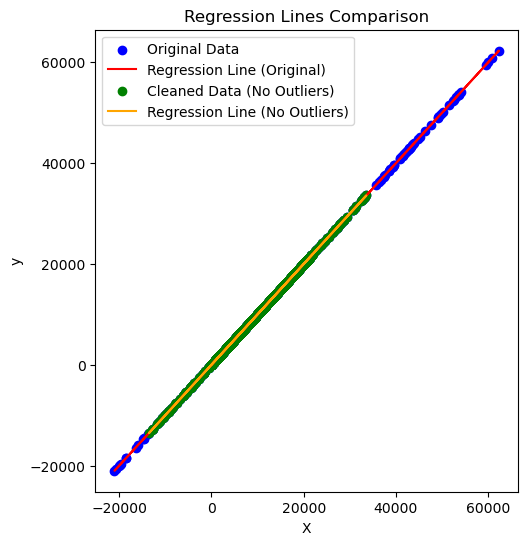

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
row_1_no_outliers = row_1[~outliers_iqr]

# آماده‌سازی داده‌ها برای رگرسیون (اضافه کردن ستون 1 برای بایاس)
X_original = np.c_[np.ones(len(row_1)), row_1.values]  # داده‌های اصلی (بدون پاکسازی)
X_cleaned_no_outliers = np.c_[np.ones(len(row_1_no_outliers)), row_1_no_outliers.values]  # داده‌های پاکسازی‌شده (حذف داده‌های پرت)

y_original = row_1.values  # برچسب‌های داده‌های اصلی
y_cleaned_no_outliers = row_1_no_outliers.values  # برچسب‌های داده‌های پاکسازی‌شده (حذف داده‌های پرت)


# آموزش مدل‌ها با داده‌های اصلی
model_original = LinearRegression()
model_original.fit(X_original[:, 1].reshape(-1, 1), y_original)

# آموزش مدل‌ها با داده‌های پاکسازی‌شده (حذف داده‌های پرت)
model_cleaned_no_outliers = LinearRegression()
model_cleaned_no_outliers.fit(X_cleaned_no_outliers[:, 1].reshape(-1, 1), y_cleaned_no_outliers)

# چاپ پارامترهای مدل‌ها
print("Model parameters for original data (LinearRegression):")
print("Intercept (B0):", model_original.intercept_)
print("Slope (B1):", model_original.coef_)

print("\nModel parameters for cleaned data (No Outliers) (LinearRegression):")
print("Intercept (B0):", model_cleaned_no_outliers.intercept_)
print("Slope (B1):", model_cleaned_no_outliers.coef_)

# رسم مدل‌ها
plt.figure(figsize=(12, 6))

# رسم داده‌های اصلی و مدل‌های رگرسیون
plt.subplot(1, 2, 1)
plt.scatter(X_original[:, 1], y_original, color='blue', label='Original Data')
plt.plot(X_original[:, 1], model_original.predict(X_original[:, 1].reshape(-1, 1)), color='red', label='Regression Line (Original)')

plt.scatter(X_cleaned_no_outliers[:, 1], y_cleaned_no_outliers, color='green', label='Cleaned Data (No Outliers)')
plt.plot(X_cleaned_no_outliers[:, 1], model_cleaned_no_outliers.predict(X_cleaned_no_outliers[:, 1].reshape(-1, 1)), color='orange', label='Regression Line (No Outliers)')

plt.title('Regression Lines Comparison')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.show()


In [59]:
# بررسی داده‌های پرت
print("Original data size:", len(row_1))
print("Cleaned data size (No outliers):", len(row_1_no_outliers))
print("Number of outliers removed:", len(row_1) - len(row_1_no_outliers))

# نمایش داده‌های پرت شناسایی شده
outliers = row_1[outliers_iqr]
print("Outliers detected:")
print(outliers)


Original data size: 2000
Cleaned data size (No outliers): 1935
Number of outliers removed: 65
Outliers detected:
1109    36210.0
1186    38739.0
1210    39540.0
1214    39633.0
1256    40962.0
         ...   
1953    53050.0
1961    42636.0
1965    42736.0
1969    42820.0
1974    53695.0
Name: 0, Length: 65, dtype: float64


Model parameters for original data (LinearRegression):
Intercept (B0): 1.8189894035458565e-12
Slope (B1): [1.]

Model parameters for cleaned data (No Outliers) (LinearRegression):
Intercept (B0): 10275.644186046511
Slope (B1): [7433.437954]

Model parameters for cleaned data (Imputation) (LinearRegression):
Intercept (B0): [-5.45696821e-12]
Slope (B1): [[1.]]


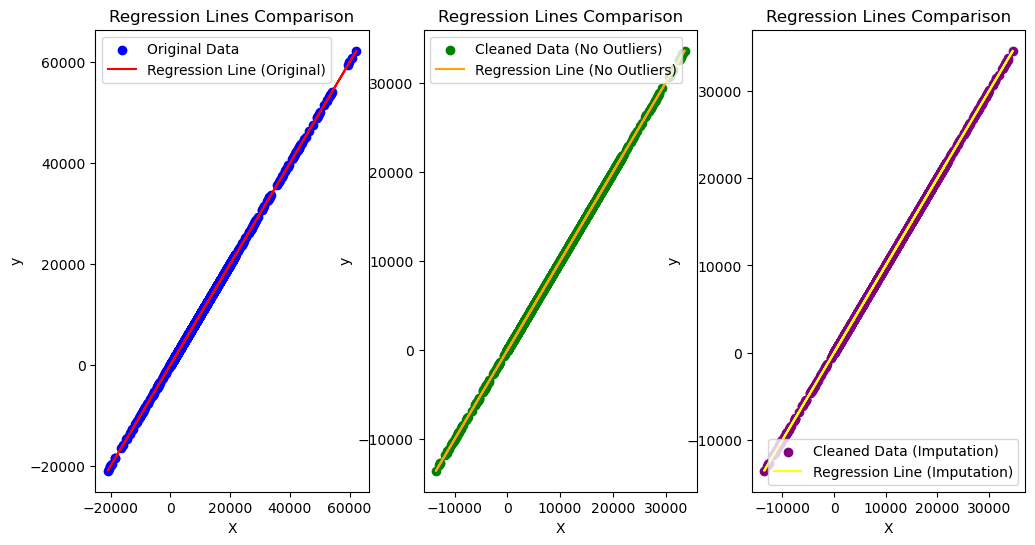

In [67]:
# آموزش مدل‌ها با داده‌های اصلی
model_original = LinearRegression()
model_original.fit(X_original[:, 1].reshape(-1, 1), y_original)

# آموزش مدل‌ها با داده‌های پاکسازی‌شده (حذف داده‌های پرت)
model_cleaned_no_outliers = LinearRegression()
model_cleaned_no_outliers.fit(X_scaled_no_outliers[:, 1].reshape(-1, 1), y_cleaned_no_outliers)

# آموزش مدل‌ها با داده‌های پاکسازی‌شده (جایگزینی با میانگین همسایه‌ها)
model_cleaned_with_imputation = LinearRegression()
model_cleaned_with_imputation.fit(X_cleaned_with_imputation[:, 1].reshape(-1, 1), y_cleaned_with_imputation)

# چاپ پارامترهای مدل‌ها
print("Model parameters for original data (LinearRegression):")
print("Intercept (B0):", model_original.intercept_)
print("Slope (B1):", model_original.coef_)

print("\nModel parameters for cleaned data (No Outliers) (LinearRegression):")
print("Intercept (B0):", model_cleaned_no_outliers.intercept_)
print("Slope (B1):", model_cleaned_no_outliers.coef_)

print("\nModel parameters for cleaned data (Imputation) (LinearRegression):")
print("Intercept (B0):", model_cleaned_with_imputation.intercept_)
print("Slope (B1):", model_cleaned_with_imputation.coef_)

# رسم مدل‌ها
plt.figure(figsize=(12, 6))

# رسم داده‌های اصلی و مدل‌های رگرسیون
plt.subplot(1, 3, 1)
plt.scatter(X_original[:, 1], y_original, color='blue', label='Original Data')
plt.plot(X_original[:, 1], model_original.predict(X_original[:, 1].reshape(-1, 1)), color='red', label='Regression Line (Original)')
plt.title('Regression Lines Comparison')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.subplot(1, 3, 2)
plt.scatter(X_cleaned_no_outliers[:, 1], y_cleaned_no_outliers, color='green', label='Cleaned Data (No Outliers)')
plt.plot(X_cleaned_no_outliers[:, 1], model_cleaned_no_outliers.predict(X_scaled_no_outliers[:, 1].reshape(-1, 1)), color='orange', label='Regression Line (No Outliers)')
plt.title('Regression Lines Comparison')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()


plt.subplot(1, 3, 3)
plt.scatter(X_cleaned_with_imputation[:, 1], y_cleaned_with_imputation, color='purple', label='Cleaned Data (Imputation)')
plt.plot(X_cleaned_with_imputation[:, 1], model_cleaned_with_imputation.predict(X_cleaned_with_imputation[:, 1].reshape(-1, 1)), color='yellow', label='Regression Line (Imputation)')
plt.title('Regression Lines Comparison')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.show()


Model parameters for RANSAC (Robust Regression):
Intercept (B0): 7.275957614183426e-12
Slope (B1): [1.]

Model parameters for TheilSen (Robust Regression):
Intercept (B0): -5.29687158144092e-15
Slope (B1): [0.99999996]


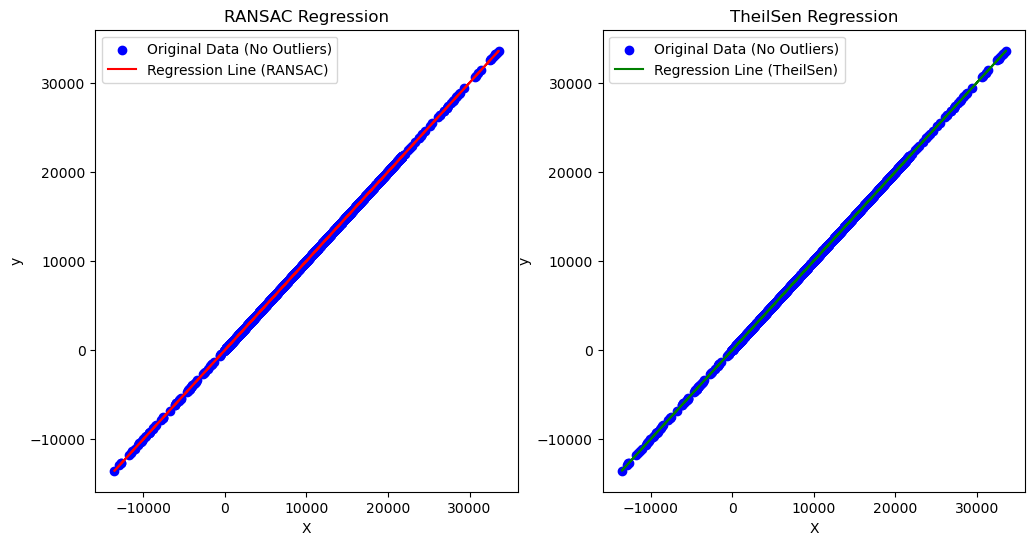

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RANSACRegressor, TheilSenRegressor
# انتخاب سطر اول دیتاست
row_1 = df.iloc[0]

# آماده‌سازی داده‌ها برای رگرسیون (اضافه کردن ستون 1 برای بایاس)
X_original = np.c_[np.ones(len(row_1)), row_1.values]  # داده‌های اصلی (بدون پاکسازی)
y_original = row_1.values  # برچسب‌های داده‌های اصلی

# شناسایی داده‌های پرت با استفاده از IQR
Q1 = np.percentile(row_1.values, 25)  # 25 درصد پایین
Q3 = np.percentile(row_1.values, 75)  # 75 درصد بالا
IQR = Q3 - Q1  # محاسبه IQR
lower_bound = Q1 - 1.5 * IQR  # حد پایین
upper_bound = Q3 + 1.5 * IQR  # حد بالا

outliers_iqr = (row_1 < lower_bound) | (row_1 > upper_bound)

# داده‌های پاکسازی‌نشده
row_1_no_outliers = row_1[~outliers_iqr]

# آماده‌سازی داده‌ها برای رگرسیون (اضافه کردن ستون 1 برای بایاس)
X_no_outliers = np.c_[np.ones(len(row_1_no_outliers)), row_1_no_outliers.values]  # داده‌های پاکسازی‌شده
y_no_outliers = row_1_no_outliers.values  # برچسب‌های داده‌های پاکسازی‌شده (حذف داده‌های پرت)

# آموزش مدل RANSAC (رگرسیون مقاوم)
ransac_model = RANSACRegressor()
ransac_model.fit(X_no_outliers[:, 1].reshape(-1, 1), y_no_outliers)

# آموزش مدل TheilSenRegressor (رگرسیون مقاوم)
theil_sen_model = TheilSenRegressor()
theil_sen_model.fit(X_no_outliers[:, 1].reshape(-1, 1), y_no_outliers)

# چاپ پارامترهای مدل‌ها
print("Model parameters for RANSAC (Robust Regression):")
print("Intercept (B0):", ransac_model.estimator_.intercept_)  # استفاده از مدل داخلی
print("Slope (B1):", ransac_model.estimator_.coef_)  # استفاده از مدل داخلی

print("\nModel parameters for TheilSen (Robust Regression):")
print("Intercept (B0):", theil_sen_model.intercept_)
print("Slope (B1):", theil_sen_model.coef_)

# رسم مدل‌ها
plt.figure(figsize=(12, 6))

# رسم مدل RANSAC
plt.subplot(1, 2, 1)
plt.scatter(X_no_outliers[:, 1], y_no_outliers, color='blue', label='Original Data (No Outliers)')
plt.plot(X_no_outliers[:, 1], ransac_model.predict(X_no_outliers[:, 1].reshape(-1, 1)), color='red', label='Regression Line (RANSAC)')
plt.title('RANSAC Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

# رسم مدل TheilSenRegressor
plt.subplot(1, 2, 2)
plt.scatter(X_no_outliers[:, 1], y_no_outliers, color='blue', label='Original Data (No Outliers)')
plt.plot(X_no_outliers[:, 1], theil_sen_model.predict(X_no_outliers[:, 1].reshape(-1, 1)), color='green', label='Regression Line (TheilSen)')
plt.title('TheilSen Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()

plt.show()


Model Comparison (MSE and MAE):
Linear Model MSE: 1.1009095998130243e-25, MAE: 2.5339597087281617e-13


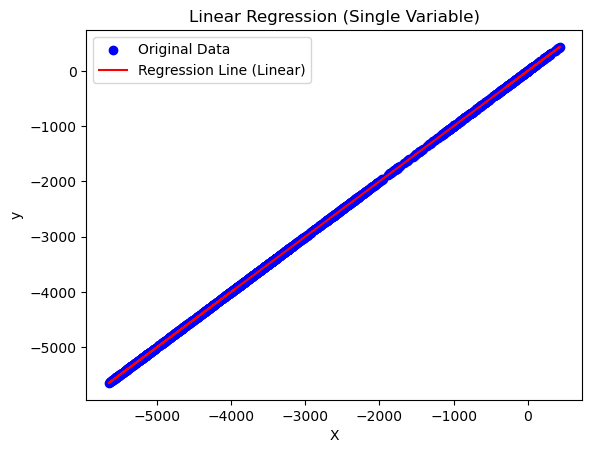

In [79]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
# انتخاب سطر سوم دیتاست
row_3 = df.iloc[2]  # سطر سوم

# آماده‌سازی داده‌ها برای رگرسیون تک متغیره
X_original = np.c_[np.ones(len(row_3)), row_3.values]  # داده‌های اصلی (بدون پاکسازی)
y_original = row_3.values  # برچسب‌های داده‌های اصلی

# آموزش مدل رگرسیون تک متغیره
linear_model = LinearRegression()
linear_model.fit(X_original[:, 1].reshape(-1, 1), y_original)

# پیش‌بینی برای مدل
linear_preds = linear_model.predict(X_original[:, 1].reshape(-1, 1))

# محاسبه MSE و MAE برای ارزیابی مدل
linear_mse = mean_squared_error(y_original, linear_preds)
linear_mae = mean_absolute_error(y_original, linear_preds)

# چاپ خطاها
print("Model Comparison (MSE and MAE):")
print(f"Linear Model MSE: {linear_mse}, MAE: {linear_mae}")

# رسم مدل رگرسیون تک متغیره
plt.scatter(X_original[:, 1], y_original, color='blue', label='Original Data')
plt.plot(X_original[:, 1], linear_preds, color='red', label='Regression Line (Linear)')
plt.title('Linear Regression (Single Variable)')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()


In [83]:
######################################################ROW2##################################################

row_2 = df.iloc[1]
row_2

1      -3980.0
2      -3883.0
3      -3832.0
4          0.0
5      -3839.0
         ...  
1996       0.0
1997    7027.0
1998    6929.0
1999    6954.0
2000    6867.0
Name: 1, Length: 2000, dtype: float64

In [91]:
row_2.isnull().sum()

0

In [85]:
# 2. پاکسازی داده‌ها با IQR:
Q1_2 = np.percentile(row_2.values, 25)  # 25 درصد پایین
Q3_2 = np.percentile(row_2.values, 75)  # 75 درصد بالا
IQR2 = Q3_2 - Q1_2  # محاسبه IQR
lower_bound2 = Q1_2 - 1.5 * IQR2  # حد پایین
upper_bound2 = Q3_2 + 1.5 * IQR2  # حد بالا

outliers_iqr2 = (row_2 < lower_bound2) | (row_2 > upper_bound2)

In [95]:
outliers_iqr2_values = row_2[outliers_iqr2]
print("detected values with IQR method: ", outliers_iqr2_values)
#اینجا هیچ داده پرتی شناسایی نشد

detected values with IQR method:  Series([], Name: 1, dtype: float64)


In [137]:
# Extract the second row
row2 = df.iloc[1, :]

# Z-Score method
z_scores2 = (row2 - row2.mean()) / row2.std()
outliers_zscore2 = row2[np.abs(z_scores2) > 3]

# IQR method
Q1 = row.quantile(0.25)
Q3 = row.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = row2[(row2 < lower_bound) | (row2 > upper_bound)]

outliers_zscore, outliers_iqr

(array([False, False, False, ..., False, False, False]),
 1003    3651.0
 1005    3657.0
 1006    3750.0
 1007    3684.0
 1008    3672.0
          ...  
 1995    7064.0
 1997    7027.0
 1998    6929.0
 1999    6954.0
 2000    6867.0
 Name: 1, Length: 636, dtype: float64)